# SCM203405 — Sistemas de Comunicação
## Laboratório: Modulação e Demodulação BFSK

**Curso:** Superior em Eletrônica Industrial – IFSC, Florianópolis



---
## 0. Preparação do ambiente

Execute a célula abaixo para importar as bibliotecas necessárias.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.special import erfc
import hashlib

plt.rcParams['figure.figsize'] = (10, 4)


---
## 1. Parâmetros individualizados

Preencha sua matrícula abaixo. A função `parametros_individualizados` deriva,
de forma determinística, um conjunto de parâmetros **único para você**: a
frequência $f_1$, a frequência $f_2$, a duração de bit $T_b$ e a sequência de
16 bits que você vai modular. Rode a célula e **não altere os valores
gerados** — todo o restante do laboratório deve usar exatamente esses
parâmetros.

In [ ]:
MATRICULA = "COLOQUE_SUA_MATRICULA_AQUI"  # ex: "20231234567"

def parametros_individualizados(matricula: str):
    """Gera parametros deterministicos (mas unicos por aluno) a partir da matricula."""
    h = hashlib.sha256(matricula.encode()).hexdigest()
    seed = int(h[:8], 16)
    rng = np.random.default_rng(seed)

    Tb = 1e-3                      # duracao de bit fixa, em segundos (1 ms)
    f1 = 2000 + (seed % 10) * 200  # Hz
    delta_min = 1 / (2 * Tb)       # espacamento minimo p/ ortogonalidade coerente
    # fator entre 0.5x e 1.5x do espacamento minimo -> para ALGUNS alunos
    # a ortogonalidade estrita nao sera satisfeita (isso e proposital, ver Secao 6)
    fator = 0.5 + (seed % 100) / 100.0
    f2 = f1 + fator * delta_min

    bits = rng.integers(0, 2, size=16)

    return {"seed": seed, "Tb": Tb, "f1": f1, "f2": f2,
            "delta_min": delta_min, "fator_delta": fator, "bits": bits}

params = parametros_individualizados(MATRICULA)
for k, v in params.items():
    print(f"{k}: {v}")


> **Atenção:** guarde o valor de `fator_delta` impresso acima — ele indica se
> a sua dupla de frequências satisfaz ou não a condição clássica de
> ortogonalidade para FSK coerente. Isso será relevante na Seção 6.

---
## 2. Modulador BFSK

Implemente o modulador BFSK coerente segundo o diagrama de blocos abaixo,
**usando exatamente os parâmetros da Seção 1** (`f1`, `f2`, `Tb`, `bits`).

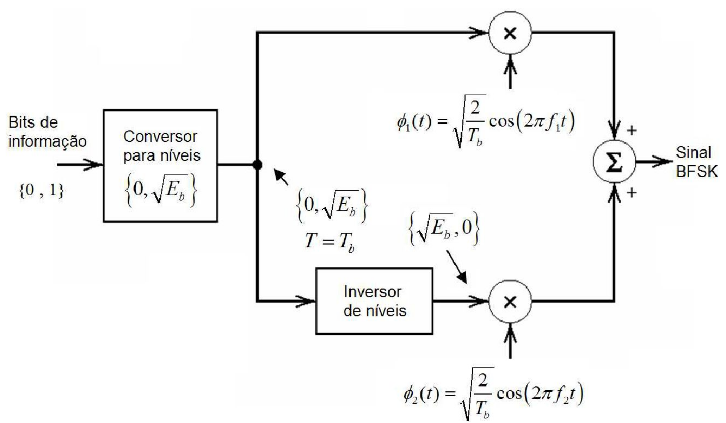

**Observações sobre os blocos:**

a) O bloco **Conversor para níveis** é apenas um codificador NRZ unipolar:
   bit 0 → nível 0; bit 1 → nível $\sqrt{E_b}$.

b) O bloco **Inversor de níveis** troca a amplitude do sinal: onde a
   amplitude é zero, a saída é $\sqrt{E_b}$; onde a amplitude é
   $\sqrt{E_b}$, a saída é zero.

c) As funções-base são:
$$\phi_1(t) = \sqrt{\frac{2}{T_b}}\cos(2\pi f_1 t), \qquad
  \phi_2(t) = \sqrt{\frac{2}{T_b}}\cos(2\pi f_2 t)$$

**O que fazer:**
1. Complete a função `modula_bfsk` abaixo (os `TODO`s).
2. Gere o sinal $s(t)$ para os 16 bits da Seção 1.
3. Plote $s(t)$ no domínio do tempo.
4. Plote o espectro de amplitude de $s(t)$ (via FFT) no domínio da
   frequência, identificando $f_1$ e $f_2$ no gráfico.

In [ ]:
Eb = 1.0            # energia de bit normalizada
fs = 200_000         # taxa de amostragem (Hz) -- ajuste se necessario

def modula_bfsk(bits, f1, f2, Tb, Eb, fs):
    """
    Retorna (t, s) onde:
      t : vetor de tempo
      s : sinal BFSK modulado, s(t)
    """
    n_amostras_por_bit = int(Tb * fs)
    t = np.arange(len(bits) * n_amostras_por_bit) / fs

    # TODO: construa phi1(t) e phi2(t) (vetores do mesmo tamanho de t)
    phi1 = None  # TODO
    phi2 = None  # TODO

    # TODO: construa o sinal de niveis (conversor NRZ unipolar) amostra-a-amostra
    nivel = None       # TODO -> sqrt(Eb) onde bit==1, 0 onde bit==0
    nivel_inv = None   # TODO -> inverso de 'nivel' (bloco Inversor de niveis)

    # TODO: monte s(t) = nivel*phi1(t) + nivel_inv*phi2(t)
    s = None  # TODO

    return t, s

t, s = modula_bfsk(params["bits"], params["f1"], params["f2"],
                    params["Tb"], Eb, fs)

# TODO: plot de s(t) no dominio do tempo

# TODO: plot do espectro de amplitude de s(t) (FFT), com f1 e f2 marcados


---
## 3. Demodulador (receptor por correlação)

Implemente o demodulador coerente segundo o diagrama abaixo, aplicado ao
sinal $s(t)$ gerado na Seção 2 (ainda **sem ruído**).

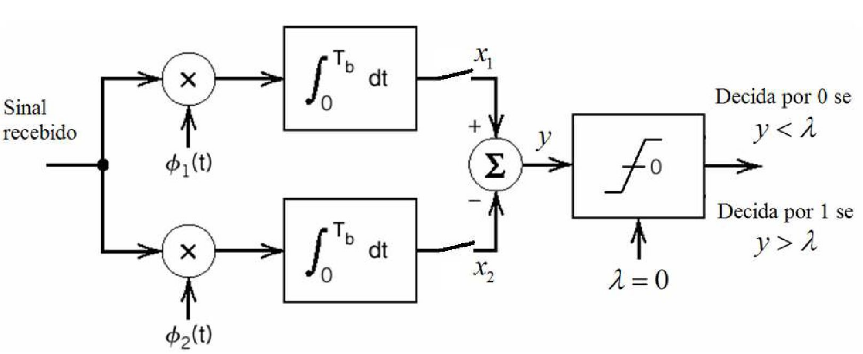

**Observações sobre os blocos:**

a) As funções-base $\phi_1(t)$ e $\phi_2(t)$ são as mesmas usadas na
   transmissão.

b) O **Correlator** multiplica o sinal recebido pela mesma função-base
   usada na modulação e integra o resultado a cada intervalo de símbolo
   $T_b$.

c) O bloco de **decisão** compara a subtração das duas projeções ($y = x_1
   - x_2$) com o limiar $\lambda = 0$: decide por 1 se $y > \lambda$, por
   0 se $y < \lambda$.

**O que fazer:**
1. Complete `demodula_bfsk`.
2. Aplique-a ao sinal da Seção 2.
3. Compare a sequência de bits demodulada com `params["bits"]` e confirme
   que são idênticas (canal ainda ideal, sem ruído).

In [ ]:
def demodula_bfsk(s, f1, f2, Tb, fs):
    """
    Retorna um array de bits demodulados a partir do sinal recebido s.
    """
    n_amostras_por_bit = int(Tb * fs)
    n_bits = len(s) // n_amostras_por_bit
    t_bit = np.arange(n_amostras_por_bit) / fs

    phi1 = None  # TODO (mesma phi1 da Secao 2)
    phi2 = None  # TODO (mesma phi2 da Secao 2)

    bits_rx = np.zeros(n_bits, dtype=int)
    for i in range(n_bits):
        trecho = s[i*n_amostras_por_bit:(i+1)*n_amostras_por_bit]
        # TODO: calcule x1 = integral(trecho * phi1) e x2 = integral(trecho * phi2)
        x1 = None  # TODO
        x2 = None  # TODO
        y = x1 - x2
        bits_rx[i] = 1 if y > 0 else 0

    return bits_rx

bits_rx = demodula_bfsk(s, params["f1"], params["f2"], params["Tb"], fs)

print("Bits originais:  ", params["bits"])
print("Bits demodulados:", bits_rx)
print("Identicos?", np.array_equal(params["bits"], bits_rx))


---
## 4. Canal com ruído (AWGN) e curva de BER

Um receptor que só funciona sem ruído não diz muito sobre um sistema de
comunicação real. Nesta seção você vai:

1. Implementar um canal AWGN que adiciona ruído gaussiano branco a $s(t)$
   para um dado $E_b/N_0$.
2. Gerar uma sequência **longa** de bits (não apenas 16 — use pelo menos
   $10^4$ bits) com os mesmos `f1`, `f2`, `Tb` da Seção 1.
3. Para uma faixa de $E_b/N_0$ (por exemplo, de 0 a 12 dB, em passos de 1
   ou 2 dB), simular transmissão + canal + recepção e calcular a BER
   (taxa de erro de bit) simulada.
4. Plotar a BER simulada (eixo y em escala log) versus $E_b/N_0$ (dB),
   **sobrepondo a curva teórica** da BFSK coerente ortogonal:
$$P_e = Q\!\left(\sqrt{\frac{E_b}{N_0}}\right), \qquad
  Q(x) = \frac{1}{2}\,\mathrm{erfc}\!\left(\frac{x}{\sqrt{2}}\right)$$

**Antes de rodar a simulação:** calcule à mão (ou em uma célula separada,
sem usar a LLM para o cálculo em si) o valor teórico de $P_e$ para pelo
menos dois pontos de $E_b/N_0$ da sua faixa, e anote o resultado em uma
célula de markdown — isso será conferido depois.

In [ ]:
def canal_awgn(s, EbN0_dB, Eb, Tb, fs):
    """Adiciona ruido gaussiano branco a s, para a relacao Eb/N0 (em dB) dada."""
    EbN0 = 10 ** (EbN0_dB / 10)
    N0 = Eb / EbN0
    var_ruido = N0 * fs / 2
    ruido = np.random.normal(0, np.sqrt(var_ruido), size=len(s))
    return s + ruido

def calcula_ber(n_bits, EbN0_dB, f1, f2, Tb, Eb, fs, rng):
    bits = rng.integers(0, 2, size=n_bits)
    t, s = modula_bfsk(bits, f1, f2, Tb, Eb, fs)
    s_ruidoso = canal_awgn(s, EbN0_dB, Eb, Tb, fs)
    bits_rx = demodula_bfsk(s_ruidoso, f1, f2, Tb, fs)
    n_erros = np.sum(bits != bits_rx)
    return n_erros / n_bits

# TODO: escolha n_bits >= 1e4 e a faixa de EbN0_dB
n_bits = None       # TODO
EbN0_dB_range = None  # TODO, ex: np.arange(0, 13, 2)

rng = np.random.default_rng(params["seed"])
ber_simulada = []  # TODO: preencha rodando calcula_ber para cada EbN0_dB

ber_teorica = 0.5 * erfc(np.sqrt(10**(np.array(EbN0_dB_range)/10)) / np.sqrt(2)) \
              if EbN0_dB_range is not None else None

# TODO: plot semilogy de ber_simulada e ber_teorica versus EbN0_dB_range


---
## 5. Ocupação espectral

Usando o sinal $s(t)$ **sem ruído** da Seção 2:

1. Estime a largura de banda ocupada pelo sinal BFSK (por exemplo, banda
   que contém 99% da energia do sinal, ou usando a regra de Carson para
   FSK).
2. Compare essa largura de banda com o espaçamento $|f_2 - f_1|$ dos seus
   parâmetros individualizados.


In [ ]:
# TODO: calcule a largura de banda ocupada (ex.: criterio de 99% de energia)
# TODO: compare com |f2 - f1|


---
## 6. Perguntas "e se...?"

Responda em células de markdown, com justificativa técnica (não apenas a
conclusão). Estas perguntas **não têm uma resposta que se obtenha apenas
rodando o código anterior** — exigem que você raciocine sobre o que
aconteceria.

1. **Ortogonalidade:** verifique se o seu `fator_delta` (Seção 1) é maior
   ou menor que 1. Se for menor que 1, suas frequências $f_1$ e $f_2$
   **não** satisfazem rigorosamente a condição clássica de ortogonalidade
   $\Delta f = 1/(2T_b)$ para detecção coerente. Isso afetou visivelmente
   a BER medida na Seção 4? Por quê (ou por que não)?

2. **E se $T_b$ dobrasse** (símbolos duas vezes mais longos), mantendo
   $f_1$, $f_2$ e $E_b/N_0$ fixos? O que aconteceria com a BER? E com a
   banda ocupada (Seção 5)? Justifique com base na teoria, não apenas
   rodando a simulação.

3. **E se o receptor não tivesse sincronismo perfeito** com o transmissor
   (ou seja, $\phi_1(t)$ e $\phi_2(t)$ usados no receptor estivessem
   levemente defasados em relação aos do transmissor)? Qual seria o efeito
   esperado sobre $x_1$ e $x_2$, e por consequência sobre a decisão?
   (Não é necessário simular — descreva o raciocínio.)



*(Escreva suas respostas aqui, uma célula markdown por item, ou numeradas dentro desta mesma célula.)*

---
## 7. Log de uso de IA

Preencha a tabela abaixo com cada interação relevante que você teve com uma
LLM (ChatGPT, Claude, Copilot, etc.) durante este laboratório. Isso é
tratado como **citação de fonte**, não como delação — o objetivo é
documentar seu processo, não penalizar o uso da ferramenta.

| # | Seção do lab | Prompt (resumo) | O que a IA sugeriu | O que você validou/mudou e por quê |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |

Adicione quantas linhas forem necessárias. Se você não usou IA em alguma
seção, não é preciso preencher uma linha para ela.

---
## 8. Entregáveis

- Este notebook preenchido (`.ipynb`), com todas as células executadas e
  os gráficos visíveis (não apenas o código).
- A célula de cálculo teórico manual da Seção 4 (os dois pontos de $P_e$
  calculados antes da simulação).
- As respostas da Seção 6 (perguntas "e se...?").
- O log de uso de IA preenchido (Seção 7).
